# EDGE Quantum Guard (EQG) — Ablación de 4 brazos (orden ABBA)

## Pregunta experimental

**¿Qué parte del stack EQG produce la mejora?**  
Misma carga que R1/R2 (MaxCut camino, **N=8, p=2**). Cuatro brazos intercalados dentro de cada job para controlar la deriva del chip.

| Brazo | Layout | DD | Reacción entre jobs |
|-------|--------|----|---------------------|
| **A** | ingenuo `[0..7]` | no | no |
| **C** | MORPH por calibración | no | no |
| **D** | MORPH por calibración | sí (forzado) | no |
| **E** | EQG completo (medido en PRE) | condicional | sí (entre bloques) |

```text
PRE(snap) -> JOB1: A C D E A C D E (+snap E) -> reacción E
         -> JOB2: E D C A E D C A -> POST(snap)
```

## Contrastes pre-registrados

| Contraste | Qué mide |
|-----------|----------|
| **C − A** | Valor del layout por calibración |
| **D − C** | Valor del DD aislado (en AR) |
| **E − C** | Valor de medir en vivo + reaccionar |
| **E − D** | Política condicional vs DD siempre on |
| **E − A** | Stack completo vs baseline (réplica controlada de R1/R2) |

**Criterio:** `SOPORTADO` solo si **z de shots ≥ 2** **y** el signo es positivo en las **4 réplicas** (2 bloques × 2 reps). Si no → `NO_CONCLUYENTE`.

## Coste y seguridad

- Estimado ≈ **19 s** de cuenta QPU (4 jobs). Tope duro **24 s**.
- `CONFIRM_SPEND = False` por defecto → no gasta QPU hasta que lo pongas en `True`.
- `MODE = "sim"` permite ensayo gratis (FakeFez/Aer).
- Durante la espera de cada job se imprime **status cada 30 s** (cola ≠ cuenta). No cancelar si ves `QUEUED` o `RUNNING`.


In [1]:
import os, sys, time, json, math, uuid, warnings, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "qiskit>=1.0", "qiskit-ibm-runtime>=0.30",
                "qiskit-aer>=0.14", "matplotlib", "scipy", "numpy"], check=False)
from pathlib import Path
from typing import Dict, List, Optional, Sequence
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ============================ PRE-REGISTRO ============================
CONFIRM_SPEND = True          # <- poner True para ejecutar en hardware
MODE = "hardware"              # "sim" para ensayo gratis (FakeFez/Aer)
BACKEND_NAME = "ibm_kingston"
SEED = 7

N_QAOA, P_LAYERS, N_RESTARTS = 8, 2, 40
SHOTS_WORK = 1500              # shots por circuito de trabajo
REPS_PER_BLOCK = 2             # repeticiones de cada brazo por job
BLOCK_ORDERS = [["A", "C", "D", "E"], ["E", "D", "C", "A"]]   # palindromo ABBA
SHOTS_SNAP_FULL, SHOTS_SNAP_LIGHT = 128, 96
PROBE_DELAY_US = 20.0
DD_SEQUENCE = "CPMG"

T_SHOT_S = 331.6e-6
OVERHEAD_S = 2.5               # por job (medido: ~2.49 s)
QPU_REMAINING_S = 40.0
HARD_CAP_S = 24.0              # no se lanza ningun job que pueda superar este acumulado

HEALTH_STABLE, HEALTH_DEGRADED = 0.65, 0.45
REL_THR, FLAG_REL = 0.85, 0.75
TARGET_INTEGRITY, REMAP_TOL, EDGE_W = 0.35, 0.05, 8.0
Z_SIG = 2.0
JOB_TIMEOUT_S = 1800

OUT = Path("/kaggle/working/eqg_ablation") if Path("/kaggle/working").exists() else Path("eqg_ablation")
OUT.mkdir(parents=True, exist_ok=True)

def est_job_s(shots):
    return OVERHEAD_S + sum(shots) * T_SHOT_S

_n_arm_circ = 4 * REPS_PER_BLOCK
EST_PRE = est_job_s([SHOTS_SNAP_FULL] * 4 * 3)
EST_BLOCK = est_job_s([SHOTS_WORK] * _n_arm_circ + [SHOTS_SNAP_LIGHT] * 3)
EST_POST = est_job_s([SHOTS_SNAP_FULL] * 4 * 4)
EST_TOTAL = EST_PRE + len(BLOCK_ORDERS) * EST_BLOCK + EST_POST
print("Estimado: PRE %.2f + %d x bloque %.2f + POST %.2f = %.2f s  (tope %.1f s, quedan %.0f s)" % (
    EST_PRE, len(BLOCK_ORDERS), EST_BLOCK, EST_POST, EST_TOTAL, HARD_CAP_S, QPU_REMAINING_S))
assert EST_TOTAL <= HARD_CAP_S, "El plan excede el tope"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 76.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.

## Salud, calibracion, Reflejos (MORPH con memoria), Juicio, Ojos


In [2]:
def _try(fn, default=None):
    try:
        v = fn()
        return default if v is None else v
    except Exception:
        return default

def cal_health(t1_us, t2_us, ro):
    t1 = t1_us if t1_us else 100.0
    t2 = t2_us if t2_us else 80.0
    ro = ro if ro is not None else 0.03
    h = 0.35 * min(t1 / 200.0, 1.0) + 0.35 * min(t2 / 150.0, 1.0) + 0.30 * (1.0 - min(ro / 0.08, 1.0))
    return float(np.clip(h, 0.02, 1.0))

def estado_from_h(h):
    return "estable" if h >= HEALTH_STABLE else ("degradado" if h >= HEALTH_DEGRADED else "inestable")

def read_cal(backend, qs, refresh=False):
    props = None
    try:
        props = backend.properties(refresh=True) if refresh else backend.properties()
    except Exception:
        props = _try(lambda: backend.properties())
    tgt = getattr(backend, "target", None)
    out = {}
    for q in qs:
        t1 = _try(lambda: props.t1(q)) if props is not None else None
        t2 = _try(lambda: props.t2(q)) if props is not None else None
        ro = _try(lambda: props.readout_error(q)) if props is not None else None
        if (t1 is None or t2 is None) and tgt is not None:
            qp = _try(lambda: tgt.qubit_properties[q])
            if qp is not None:
                t1 = t1 if t1 is not None else getattr(qp, "t1", None)
                t2 = t2 if t2 is not None else getattr(qp, "t2", None)
        if ro is None and tgt is not None:
            ro = _try(lambda: tgt["measure"][(q,)].error)
        out[int(q)] = {"t1_us": None if t1 is None else float(t1) * 1e6,
                       "t2_us": None if t2 is None else float(t2) * 1e6,
                       "ro": None if ro is None else float(ro)}
    stamp = _try(lambda: str(props.last_update_date), "desconocido") if props is not None else "desconocido"
    return out, stamp

def read_edge_err(backend):
    err, tgt = {}, getattr(backend, "target", None)
    if tgt is None:
        return err
    for g in ("cz", "ecr", "cx"):
        if g in tgt.operation_names:
            for qargs, inst in tgt[g].items():
                if inst is not None and getattr(inst, "error", None) is not None and len(qargs) == 2:
                    err[frozenset((int(qargs[0]), int(qargs[1])))] = float(inst.error)
            if err:
                break
    return err

def coupling_edges(backend):
    edges = []
    try:
        cm = backend.coupling_map
        if cm is not None:
            edges = [(int(a), int(b)) for a, b in cm.get_edges()]
    except Exception:
        pass
    return edges or [(i, i + 1) for i in range(15)]

class Reflejos:
    """MORPH: mejor camino fisico conectado de k qubits. Con memoria: excluye qubits ya marcados."""
    def __init__(self):
        self.blacklist = set()
    def score_path(self, path, hm, edge_err):
        h = float(np.mean([hm[q] for q in path]))
        es = [edge_err.get(frozenset((a, b)), 0.01) for a, b in zip(path[:-1], path[1:])]
        return h - EDGE_W * (float(np.mean(es)) if es else 0.0)
    def select(self, hm, edges, edge_err, k, exclude=(), beam=200):
        excl = set(exclude)
        ok = {q for q, h in hm.items() if estado_from_h(h) != "inestable" and q not in excl}
        adj = {q: set() for q in ok}
        for a, b in edges:
            if a in ok and b in ok:
                adj[a].add(b); adj[b].add(a)
        frontier = [[q] for q in sorted(ok)]
        for _ in range(k - 1):
            nxt = [p + [n] for p in frontier for n in adj[p[-1]] if n not in p]
            if not nxt:
                return None
            nxt.sort(key=lambda p: -self.score_path(p, hm, edge_err))
            frontier = nxt[:beam]
        best = max(frontier, key=lambda p: self.score_path(p, hm, edge_err))
        return {"selected": list(best), "score": self.score_path(best, hm, edge_err)}

def layout_connected(layout, edges):
    es = {frozenset(e) for e in edges}
    return all(frozenset((a, b)) in es for a, b in zip(layout[:-1], layout[1:]))

class AOMMembrane:
    def __init__(self, capacity=4, lo=0.25, hi=0.45):
        self.buf, self.cap, self.lo, self.hi, self.regime = [], capacity, lo, hi, "ESTABLE"
    def push(self, f):
        self.buf = (self.buf + [f])[-self.cap:]
        sm = f if len(self.buf) == 1 else 0.6 * f + 0.4 * (sum(self.buf[:-1]) / (len(self.buf) - 1))
        r = self.regime
        if r == "ESTABLE":
            self.regime = "CONFLICTO" if sm >= 0.70 else ("INESTABLE" if sm >= self.hi else r)
        elif r == "INESTABLE":
            self.regime = "ESTABLE" if sm < self.lo else ("CONFLICTO" if sm >= 0.70 else r)
        else:
            self.regime = "ESTABLE" if sm < self.lo else ("INESTABLE" if sm < self.hi else r)
        return self.regime, sm

class Ojos:
    def __init__(self):
        self.membrane = AOMMembrane()
    def observe(self, qubits, hm, rel_mean=None, flagged=None):
        qs = [int(q) for q in qubits]
        raw = float(np.mean([1.0 - hm[q] for q in qs]))
        if rel_mean is not None:
            raw = 1.0 - float(np.clip(rel_mean, 0.0, 1.0))
        regime, sm = self.membrane.push(raw)
        est = [estado_from_h(hm[q]) for q in qs]
        return {"friction": raw, "smoothed": sm, "regime": regime,
                "n_degradado": est.count("degradado"), "n_inestable": est.count("inestable"),
                "n_estable": est.count("estable"), "health_mean": float(np.mean([hm[q] for q in qs])),
                "rel_mean": rel_mean, "flagged": list(flagged or [])}

def planificar(lh, layout, alt, cur_score):
    flagged = lh["flagged"]
    need_dd = ((lh["rel_mean"] is not None and lh["rel_mean"] < REL_THR) or (lh["n_degradado"] + lh["n_inestable"]) > 0
               or lh["health_mean"] < HEALTH_STABLE or bool(flagged))
    remap = bool(flagged) and alt is not None and alt["score"] >= cur_score - REMAP_TOL and set(alt["selected"]) != set(layout)
    calm = (not need_dd) and (not flagged)
    opts = [dict(tipo="ninguna", cost=0.0, gain=0.55 if calm else 0.0, reason="regimen estable; no intervenir" if calm else "no intervenir")]
    if need_dd:
        opts.append(dict(tipo="dd_condicional", cost=0.25, gain=0.30 if flagged else 0.55, reason="DD condicional por coherencia/salud"))
    if remap:
        opts.append(dict(tipo="remap_morph", cost=0.40, gain=0.90, reason="qubits %s marcados; remap %s" % (flagged, alt["selected"])))
    if lh["regime"] == "CONFLICTO" and lh["n_estable"] == 0:
        opts.append(dict(tipo="abortar", cost=0.0, gain=0.1, reason="CONFLICTO sin qubits estables"))
    elig = [o for o in opts if o["gain"] >= TARGET_INTEGRITY]
    ch = min(elig, key=lambda o: o["cost"]) if elig else max(opts, key=lambda o: o["gain"] / max(o["cost"], 0.01))
    t = ch["tipo"]
    return {"tipo": t, "layout": list(alt["selected"]) if t == "remap_morph" else list(layout),
            "activate_dd": t in ("dd_condicional", "remap_morph") and need_dd, "reason": ch["reason"]}


## Manos: DD + snapshots por qubit


In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XGate, YGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling

def apply_dd(tcs, backend, qubits):
    seq = [XGate(), XGate()]          # CPMG
    target = backend.target
    pm = PassManager([ALAPScheduleAnalysis(target=target),
                      PadDynamicalDecoupling(target=target, dd_sequence=seq, qubits=[int(q) for q in qubits],
                                             pulse_alignment=getattr(target, "pulse_alignment", 1), skip_reset_qubits=False)])
    out, added = [], 0
    cnt = lambda c: int(c.count_ops().get("x", 0) + c.count_ops().get("y", 0))
    for tc in tcs:
        try:
            tc2 = pm.run(tc)
        except Exception as e:
            print("[DD] ERROR (%s) -> circuito sin DD" % e); tc2 = tc
        added += cnt(tc2) - cnt(tc); out.append(tc2)
    return out, added

def probe_delay(backend, us=PROBE_DELAY_US):
    dt = getattr(backend, "dt", None)
    if not dt:
        return float(us), "us"
    g = int(getattr(getattr(backend, "target", None), "granularity", 16) or 16)
    return max(g, int(round(us * 1e-6 / dt / g)) * g), "dt"

KINDS_LIGHT, KINDS_FULL = ["X", "Y", "Z1"], ["X", "Y", "Z1", "Z0"]

def snap_circuits(n, delay, unit, full):
    out = []
    for k in (KINDS_FULL if full else KINDS_LIGHT):
        qc = QuantumCircuit(n, n, name="snap_" + k)
        for i in range(n):
            if k in ("X", "Y"): qc.h(i)
            elif k == "Z1": qc.x(i)
        qc.barrier()
        for i in range(n): qc.delay(delay, i, unit=unit)
        qc.barrier()
        for i in range(n):
            if k == "Y": qc.sdg(i)
            if k in ("X", "Y"): qc.h(i)
        qc.measure(range(n), range(n))
        out.append(qc)
    return out

def bit_marginals(counts, n):
    tot = sum(counts.values()) or 1
    m = np.zeros(n)
    for k, v in counts.items():
        s = str(k).replace(" ", "")
        if s.startswith("0x"): s = format(int(s, 16), "0%db" % n)
        s = s.zfill(n)[-n:][::-1]
        for b in range(n):
            if s[b] == "1": m[b] += v
    return m / tot, tot

def analyze_snap(cts, layout, cal, delay_us=PROBE_DELAY_US):
    n = len(layout)
    pX, N = bit_marginals(cts["X"], n); pY, _ = bit_marginals(cts["Y"], n); p1, _ = bit_marginals(cts["Z1"], n)
    x, y = 1 - 2 * pX, 1 - 2 * pY
    coh = np.minimum(np.hypot(x, y), 1.0)
    sx = 2 * np.sqrt(np.clip(pX * (1 - pX), 1e-4, None) / N); sy = 2 * np.sqrt(np.clip(pY * (1 - pY), 1e-4, None) / N)
    se_coh = np.sqrt((x * sx) ** 2 + (y * sy) ** 2) / np.maximum(coh, 0.3)
    se_p1 = np.sqrt(np.clip(p1 * (1 - p1), 1e-4, None) / N)
    s = np.sqrt(np.clip(coh * p1, 1e-6, None))
    se_s = 0.5 * s * np.sqrt((se_coh / np.maximum(coh, 0.3)) ** 2 + (se_p1 / np.maximum(p1, 0.3)) ** 2)
    c = [cal.get(int(q), {}) for q in layout]
    t1 = np.array([(d.get("t1_us") or 100.0) for d in c]); t2 = np.array([(d.get("t2_us") or 80.0) for d in c])
    ro = np.array([(d.get("ro") if d.get("ro") is not None else 0.03) for d in c])
    exp_s = np.sqrt(np.exp(-delay_us / t2) * np.exp(-delay_us / t1) * (1 - ro))
    s_rel, se_rel = s / exp_s, se_s / exp_s
    res = {"layout": [int(q) for q in layout], "shots": int(N), "s": s.tolist(), "se_s": se_s.tolist(), "s_rel": s_rel.tolist(),
           "mean_s": float(s.mean()), "se_mean_s": float(np.sqrt((se_s ** 2).sum()) / n), "mean_rel": float(s_rel.mean()),
           "flagged": [int(q) for q, a, e in zip(layout, s_rel, se_rel) if a + Z_SIG * e < FLAG_REL]}
    if "Z0" in cts:
        e0, _ = bit_marginals(cts["Z0"], n); res["mean_e0"] = float(e0.mean())
    return res


## Carga QAOA (identica a R1/R2) y ejecucion


In [4]:
from scipy.optimize import minimize

EDGES = [(i, i + 1) for i in range(N_QAOA - 1)]
_X = np.arange(2 ** N_QAOA)
BITS = ((_X[:, None] >> np.arange(N_QAOA)) & 1).astype(np.int8)
CV = np.zeros(2 ** N_QAOA)
for (i, j) in EDGES:
    CV += (BITS[:, i] != BITS[:, j])
C_OPT = float(CV.max()); OPT_SET = np.where(np.isclose(CV, C_OPT))[0]

def _mixer(psi, b, n):
    c, s = np.cos(b), -1j * np.sin(b)
    t = psi.reshape((2,) * n)
    for ax in range(n):
        t0, t1 = np.take(t, 0, axis=ax), np.take(t, 1, axis=ax)
        t = np.stack([c * t0 + s * t1, s * t0 + c * t1], axis=ax)
    return t.reshape(-1)

def qaoa_state(theta, n=N_QAOA, p=P_LAYERS):
    g, b = theta[:p], theta[p:]
    psi = np.full(2 ** n, 1.0 / np.sqrt(2 ** n), dtype=complex)
    for l in range(p):
        psi = psi * np.exp(-1j * g[l] * CV); psi = _mixer(psi, b[l], n)
    return psi

_rng = np.random.default_rng(SEED); _best = None
for _ in range(N_RESTARTS):
    th0 = np.concatenate([_rng.uniform(0, np.pi, P_LAYERS), _rng.uniform(0, np.pi / 2, P_LAYERS)])
    r = minimize(lambda th: -float(np.sum(np.abs(qaoa_state(th)) ** 2 * CV)), th0, method="COBYLA", options={"maxiter": 500})
    if _best is None or r.fun < _best.fun: _best = r
THETA = np.array(_best.x); GAMMAS, BETAS = THETA[:P_LAYERS], THETA[P_LAYERS:]
_P = np.abs(qaoa_state(THETA)) ** 2
IDEAL = {"ar": float(_P @ CV) / C_OPT, "p_opt": float(_P[OPT_SET].sum())}
print("QAOA N=%d p=%d  C_opt=%.1f  AR ideal=%.4f  P(opt) ideal=%.4f" % (N_QAOA, P_LAYERS, C_OPT, IDEAL["ar"], IDEAL["p_opt"]))

def qaoa_circuit():
    qc = QuantumCircuit(N_QAOA, N_QAOA, name="work_qaoa")
    for i in range(N_QAOA): qc.h(i)
    for l in range(P_LAYERS):
        for (i, j) in EDGES: qc.rzz(-float(GAMMAS[l]), i, j)
        for i in range(N_QAOA): qc.rx(2.0 * float(BETAS[l]), i)
    qc.measure(range(N_QAOA), range(N_QAOA))
    return qc

def analyze_work(counts):
    n = N_QAOA; P = np.zeros(2 ** n); tot = 0
    for k, v in counts.items():
        s = str(k).replace(" ", ""); x = int(s, 16) if s.startswith("0x") else int(s, 2)
        P[x] += v; tot += v
    N = max(tot, 1); P = P / N
    cost = float(P @ CV); var = max(float(P @ (CV ** 2)) - cost ** 2, 0.0); se = math.sqrt(var / N)
    return {"shots": int(N), "ar": cost / C_OPT, "se_ar": se / C_OPT, "p_opt": float(P[OPT_SET].sum())}

_job_log, _SIM = [], {}

def get_backend():
    if MODE == "sim":
        from qiskit_ibm_runtime.fake_provider import FakeFez
        return FakeFez()
    from qiskit_ibm_runtime import QiskitRuntimeService
    tok = os.environ.get("IBM_QUANTUM_TOKEN") or os.environ.get("QISKIT_IBM_TOKEN")
    if not tok:
        from kaggle_secrets import UserSecretsClient
        tok = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
    try:
        svc = QiskitRuntimeService(channel="ibm_cloud", token=tok.strip(), instance="open-instance")
    except Exception:
        svc = QiskitRuntimeService(token=tok.strip())
    return svc.backend(BACKEND_NAME)

def _job_usage(job):
    for fn in (lambda: job.usage(), lambda: job.metrics()["usage"]["quantum_seconds"], lambda: job.metrics()["usage"]["seconds"]):
        v = _try(fn)
        if v is not None:
            try: return float(v), True
            except Exception: pass
    return None, False

USED_S = 0.0   # cuenta QPU acumulada (reportada por IBM; estimada si falta)

def execute_pubs(tcs, shots_list, label):
    """Un job con lista de PUBs. Aplica el tope duro ANTES de lanzar."""
    global USED_S
    est = est_job_s(shots_list)
    if USED_S + est > HARD_CAP_S:
        raise RuntimeError("Tope duro: %.2f usados + %.2f estimados > %.1f s. No se lanza %s" % (USED_S, est, HARD_CAP_S, label))
    t0 = time.time()
    if MODE == "sim":
        from qiskit_aer import AerSimulator
        if "sim" not in _SIM:
            _SIM["sim"] = AerSimulator.from_backend(backend)
        counts = [_SIM["sim"].run(tc, shots=int(s)).result().get_counts() for tc, s in zip(tcs, shots_list)]
        u, real = est, False; jid = "sim-" + label
    else:
        from qiskit_ibm_runtime import SamplerV2
        job = SamplerV2(mode=backend).run([(tc, None, int(s)) for tc, s in zip(tcs, shots_list)])
        jid = job.job_id(); print("  job %s: %s" % (label, jid))
        print("  (esperando cola/ejecucion; status cada 30s; no cancelar si QUEUED/RUNNING)", flush=True)
        t_last = time.time()
        while True:
            st = job.status()
            nm = st if isinstance(st, str) else getattr(st, "name", str(st))
            if nm in ("DONE", "CANCELLED", "ERROR"):
                break
            if time.time() - t0 > JOB_TIMEOUT_S:
                _try(lambda: job.cancel())
                raise TimeoutError(label)
            if time.time() - t_last >= 30.0:
                print("  … %s status=%s  waited=%.0fs  (cola ≠ cuenta QPU)" % (
                    label, nm, time.time() - t0), flush=True)
                t_last = time.time()
            time.sleep(2)
        if nm != "DONE": raise RuntimeError("job %s en estado %s" % (jid, nm))
        res = job.result(); counts = []
        for i in range(len(tcs)):
            data = res[i].data; c = None
            for key in ("c", "meas"):
                if hasattr(data, key):
                    try: c = getattr(data, key).get_counts(); break
                    except Exception: pass
            if c is None:
                for key in data:
                    try: c = data[key].get_counts(); break
                    except Exception: continue
            counts.append(c or {})
        u, real = _job_usage(job)
        if u is None: u, real = est, False
    USED_S += float(u)
    info = {"label": label, "job_id": jid, "usage_s": float(u), "usage_real": real, "est_s": est, "used_acum_s": USED_S}
    _job_log.append(info)
    print("  [%s] uso=%.2fs (%s) est=%.2fs acumulado=%.2fs" % (label, u, "IBM" if real else "estimado", est, USED_S))
    return counts, info

def snapshot_job(tag, variants):
    delay, unit = probe_delay(backend); tcs, shots, spec = [], [], []
    for name, layout, dd in variants:
        tc = transpile(snap_circuits(N_QAOA, delay, unit, True), backend, initial_layout=list(layout), optimization_level=1, seed_transpiler=SEED)
        if dd: tc, _ = apply_dd(tc, backend, layout)
        tcs += tc; shots += [SHOTS_SNAP_FULL] * len(tc); spec.append((name, layout, dd))
    counts, info = execute_pubs(tcs, shots, "snap-" + tag)
    out, i = {}, 0
    for name, layout, dd in spec:
        cts = {k: counts[i + j] for j, k in enumerate(KINDS_FULL)}; i += len(KINDS_FULL)
        a = analyze_snap(cts, layout, CAL0); a.update({"name": name, "dd": bool(dd)}); out[name] = a
        print("   %-5s s=%.3f+-%.3f s_rel=%.3f e0=%.3f marcados=%s" % (name, a["mean_s"], a["se_mean_s"], a["mean_rel"], a["mean_e0"], a["flagged"]))
    return {"tag": tag, "variants": out, "info": info}


QAOA N=8 p=2  C_opt=7.0  AR ideal=0.8559  P(opt) ideal=0.2849


## Preparacion (gratis): backend, calibracion y layouts


In [5]:
assert CONFIRM_SPEND or MODE == "sim", "Pon CONFIRM_SPEND = True para gastar cuenta QPU (estimado %.1f s)." % EST_TOTAL
backend = get_backend()
BACKEND = getattr(backend, "name", str(backend))
NQ = int(getattr(backend, "num_qubits", 156)); ALLQ = list(range(NQ))
CAL0, CAL_STAMP0 = read_cal(backend, ALLQ)
EDGE_ERR, EDGES_HW = read_edge_err(backend), coupling_edges(backend)
HEALTH0 = {q: cal_health(CAL0[q]["t1_us"], CAL0[q]["t2_us"], CAL0[q]["ro"]) for q in ALLQ}

reflejos = Reflejos()
_m = reflejos.select(HEALTH0, EDGES_HW, EDGE_ERR, N_QAOA)
LAYOUT_C = list(_m["selected"]); LAYOUT_A = list(range(N_QAOA))
print("Calibracion:", CAL_STAMP0)
print("Layout A (ingenuo):", LAYOUT_A, " Layout C/D (calibracion):", LAYOUT_C, " conectado:", layout_connected(LAYOUT_C, EDGES_HW))

def blend_health(hm0, layout, snap):
    hm = dict(hm0)
    for q, sr in zip(layout, snap["s_rel"]):
        hm[q] = 0.5 * hm0[q] + 0.5 * float(np.clip(sr, 0.0, 1.0))
    return hm

ojos_E = Ojos()
def reaction(layout, snap):
    """Ojos(medida) -> Reflejos(alternativa, con memoria) -> Juicio. Devuelve plan."""
    hm = blend_health(HEALTH0, layout, snap)
    lh = ojos_E.observe(layout, hm, rel_mean=snap["mean_rel"], flagged=snap["flagged"])
    reflejos.blacklist |= set(snap["flagged"])
    alt = reflejos.select(hm, EDGES_HW, EDGE_ERR, N_QAOA, exclude=reflejos.blacklist) if snap["flagged"] else None
    plan = planificar(lh, layout, alt, reflejos.score_path(layout, hm, EDGE_ERR))
    plan["regime"] = lh["regime"]
    return plan


qiskit_runtime_service._discover_account:WARNING:2026-10-12 08:28:38,931: Loading account with the given token. A saved account will not be used.


Calibracion: 2026-10-12 08:05:44+00:00
Layout A (ingenuo): [0, 1, 2, 3, 4, 5, 6, 7]  Layout C/D (calibracion): [50, 51, 58, 71, 70, 69, 68, 67]  conectado: True


## PRE (snapshot) y plan inicial de E


In [6]:
print("=" * 60 + "\nPRE\n" + "=" * 60)
snap_pre = snapshot_job("PRE", [("C", LAYOUT_C, False), ("C+DD", LAYOUT_C, True), ("A", LAYOUT_A, False)])
plan0 = reaction(LAYOUT_C, snap_pre["variants"]["C"])
if plan0["tipo"] == "abortar":
    raise RuntimeError("Juicio abortó en PRE: " + plan0["reason"])
LAYOUT_E, DD_E = list(plan0["layout"]), bool(plan0["activate_dd"])
print("E plan inicial: %s | DD=%s | layout=%s | %s" % (plan0["tipo"], DD_E, LAYOUT_E, plan0["reason"]))


PRE
  job snap-PRE: db69kg4vf2bc73d0si1g
  (esperando cola/ejecucion; status cada 30s; no cancelar si QUEUED/RUNNING)
  [snap-PRE] uso=3.00s (IBM) est=3.01s acumulado=3.00s
   C     s=0.840+-0.012 s_rel=0.928 e0=0.007 marcados=[]
   C+DD  s=0.870+-0.011 s_rel=0.960 e0=0.052 marcados=[]
   A     s=0.697+-0.017 s_rel=0.814 e0=0.109 marcados=[1]
E plan inicial: ninguna | DD=False | layout=[50, 51, 58, 71, 70, 69, 68, 67] | regimen estable; no intervenir


## Bloques intercalados (A C D E A C D E | E D C A E D C A)


In [7]:
works, e_snaps, plans_E = [], [], [plan0]
dd_pulses = {"A": 0, "C": 0, "D": 0, "E": 0}
cz_count = {}

def arm_config(layout_e, dd_e):
    return {"A": (LAYOUT_A, False), "C": (LAYOUT_C, False), "D": (LAYOUT_C, True), "E": (layout_e, dd_e)}

def run_block(bi, order, layout_e, dd_e):
    cfg = arm_config(layout_e, dd_e); tcs_arm = {}
    for arm in "ACDE":
        layout, dd = cfg[arm]
        tc = transpile(qaoa_circuit(), backend, initial_layout=list(layout), optimization_level=1, seed_transpiler=SEED)
        n_dd = 0
        if dd:
            tcl, n_dd = apply_dd([tc], backend, layout); tc = tcl[0]
        dd_pulses[arm] += n_dd * REPS_PER_BLOCK
        ops = tc.count_ops(); cz_count[arm] = int(sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr", "rzz")))
        tcs_arm[arm] = tc
    items = [(arm, rep) for rep in range(REPS_PER_BLOCK) for arm in order]
    tcs = [tcs_arm[a] for a, _ in items]; shots = [SHOTS_WORK] * len(items)
    delay, unit = probe_delay(backend)
    snap_tc = transpile(snap_circuits(N_QAOA, delay, unit, False), backend, initial_layout=list(layout_e), optimization_level=1, seed_transpiler=SEED)
    tcs += list(snap_tc); shots += [SHOTS_SNAP_LIGHT] * len(snap_tc)
    print("[bloque %d] orden=%s  E: layout=%s DD=%s  CZ/circ=%s" % (bi + 1, "".join(order) * REPS_PER_BLOCK, layout_e, dd_e, cz_count))
    counts, info = execute_pubs(tcs, shots, "bloque%d" % (bi + 1))
    for idx, (arm, rep) in enumerate(items):
        w = analyze_work(counts[idx]); w.update({"arm": arm, "block": bi, "rep": rep, "pos": idx, "layout": list(cfg[arm][0]), "dd": cfg[arm][1]})
        works.append(w)
        print("   %s b%d r%d pos%d AR=%.4f+-%.4f P(opt)=%.3f" % (arm, bi + 1, rep, idx, w["ar"], w["se_ar"], w["p_opt"]))
    k0 = len(items)
    cts = {k: counts[k0 + i] for i, k in enumerate(KINDS_LIGHT)}
    a = analyze_snap(cts, layout_e, CAL0); a["block"] = bi; e_snaps.append(a)
    return a

for bi, order in enumerate(BLOCK_ORDERS):
    snap_e = run_block(bi, order, LAYOUT_E, DD_E)
    if bi < len(BLOCK_ORDERS) - 1:
        pl = reaction(LAYOUT_E, snap_e); plans_E.append(pl)
        if pl["tipo"] == "abortar":
            print("Juicio: ABORTAR -> se detiene"); break
        print("E reaccion: %s | DD=%s | layout=%s | %s" % (pl["tipo"], pl["activate_dd"], pl["layout"], pl["reason"]))
        LAYOUT_E, DD_E = list(pl["layout"]), bool(pl["activate_dd"])


[bloque 1] orden=ACDEACDE  E: layout=[50, 51, 58, 71, 70, 69, 68, 67] DD=False  CZ/circ={'A': 28, 'C': 28, 'D': 28, 'E': 28}
  job bloque1: db69klamb58s738bfei0
  (esperando cola/ejecucion; status cada 30s; no cancelar si QUEUED/RUNNING)
  [bloque1] uso=5.00s (IBM) est=6.57s acumulado=8.00s
   A b1 r0 pos0 AR=0.7658+-0.0039 P(opt)=0.130
   C b1 r0 pos1 AR=0.8212+-0.0038 P(opt)=0.239
   D b1 r0 pos2 AR=0.8114+-0.0038 P(opt)=0.207
   E b1 r0 pos3 AR=0.8150+-0.0038 P(opt)=0.219
   A b1 r1 pos4 AR=0.7682+-0.0038 P(opt)=0.131
   C b1 r1 pos5 AR=0.8242+-0.0036 P(opt)=0.238
   D b1 r1 pos6 AR=0.8151+-0.0037 P(opt)=0.228
   E b1 r1 pos7 AR=0.8154+-0.0039 P(opt)=0.242
E reaccion: ninguna | DD=False | layout=[50, 51, 58, 71, 70, 69, 68, 67] | regimen estable; no intervenir
[bloque 2] orden=EDCAEDCA  E: layout=[50, 51, 58, 71, 70, 69, 68, 67] DD=False  CZ/circ={'A': 28, 'C': 28, 'D': 28, 'E': 28}
  job bloque2: db69koclf4us73c50tc0
  (esperando cola/ejecucion; status cada 30s; no cancelar si QUEU

## POST (snapshot)


In [8]:
print("=" * 60 + "\nPOST\n" + "=" * 60)
VAR_POST = [("C", LAYOUT_C, False), ("C+DD", LAYOUT_C, True), ("A", LAYOUT_A, False)]
if set(LAYOUT_E) != set(LAYOUT_C): VAR_POST.append(("E", LAYOUT_E, False))
snap_post = snapshot_job("POST", VAR_POST)


POST
  job snap-POST: db69ksamb58s738bferg
  (esperando cola/ejecucion; status cada 30s; no cancelar si QUEUED/RUNNING)
  … snap-POST status=RUNNING  waited=31s  (cola ≠ cuenta QPU)
  … snap-POST status=RUNNING  waited=63s  (cola ≠ cuenta QPU)
  … snap-POST status=RUNNING  waited=95s  (cola ≠ cuenta QPU)
  … snap-POST status=RUNNING  waited=127s  (cola ≠ cuenta QPU)
  [snap-POST] uso=3.00s (IBM) est=3.01s acumulado=16.00s
   C     s=0.860+-0.012 s_rel=0.949 e0=0.010 marcados=[]
   C+DD  s=0.872+-0.010 s_rel=0.963 e0=0.048 marcados=[]
   A     s=0.726+-0.017 s_rel=0.848 e0=0.097 marcados=[1]


## Analisis: contrastes por brazo


In [9]:
def arm_stats(arm):
    ws = [w for w in works if w["arm"] == arm]
    ar = np.array([w["ar"] for w in ws]); se = np.array([w["se_ar"] for w in ws])
    return {"n": len(ws), "ar": float(ar.mean()), "se": float(np.sqrt((se ** 2).sum()) / len(se)),
            "p_opt": float(np.mean([w["p_opt"] for w in ws])), "shots": int(sum(w["shots"] for w in ws)),
            "by_block": {b: float(np.mean([w["ar"] for w in ws if w["block"] == b])) for b in sorted({w["block"] for w in ws})}}

def contrast(X, Y):
    wx = {(w["block"], w["rep"]): w for w in works if w["arm"] == X}
    wy = {(w["block"], w["rep"]): w for w in works if w["arm"] == Y}
    ks = sorted(set(wx) & set(wy))
    d = np.array([wx[k]["ar"] - wy[k]["ar"] for k in ks]); se = np.array([math.hypot(wx[k]["se_ar"], wy[k]["se_ar"]) for k in ks])
    dm, se_p = float(d.mean()), float(np.sqrt((se ** 2).sum()) / len(d)); z = dm / se_p
    sd = float(d.std(ddof=1)) if len(d) > 1 else float("nan")
    t = dm / (sd / math.sqrt(len(d))) if sd and sd == sd and sd > 0 else float("nan")
    npos = int((d > 0).sum())
    v = "SOPORTADO" if (z >= Z_SIG and npos == len(d)) else ("SIGNO_OPUESTO" if (z <= -Z_SIG and npos == 0) else "NO_CONCLUYENTE")
    return {"contrast": "%s-%s" % (X, Y), "delta": dm, "se": se_p, "z_shots": z, "t_replicas": t, "positivas": "%d/%d" % (npos, len(d)),
            "por_replica": d.tolist(), "veredicto": v}

STATS = {a: arm_stats(a) for a in "ACDE"}
print("=" * 78 + "\nAR por brazo (ideal %.4f)\n" % IDEAL["ar"] + "=" * 78)
for a in "ACDE":
    s = STATS[a]
    print("%s  AR=%.4f+-%.4f  P(opt)=%.3f  shots=%d  por bloque=%s" % (a, s["ar"], s["se"], s["p_opt"], s["shots"],
          {b: round(v, 4) for b, v in s["by_block"].items()}))
CONTRASTS = [contrast(*p) for p in (("C", "A"), ("D", "C"), ("E", "C"), ("E", "D"), ("E", "A"))]
print("\n" + "=" * 78 + "\nContrastes (pre-registrado: z>=2 y signo + en todas las replicas)\n" + "=" * 78)
for c in CONTRASTS:
    print("%-4s delta=%+.4f+-%.4f z=%+.1f t_rep=%+.1f positivas=%s  -> %s" % (
        c["contrast"], c["delta"], c["se"], c["z_shots"], c["t_replicas"], c["positivas"], c["veredicto"]))

print("\nPulsos DD insertados (acum. por brazo):", dd_pulses, " | CZ por circuito:", cz_count)
print("Trayectoria de E:", [(p["tipo"], p["activate_dd"], p["layout"]) for p in plans_E])
print("E layout final: %s (DD=%s)" % (LAYOUT_E, DD_E))
print("e0 PRE:", {k: round(v["mean_e0"], 3) for k, v in snap_pre["variants"].items()})
print("e0 POST:", {k: round(v["mean_e0"], 3) for k, v in snap_post["variants"].items()})
print("\nCuenta QPU: usada=%.2f s (reportada IBM en %d/%d jobs) | estimada=%.2f s | tope=%.1f s | restante aprox=%.1f s" % (
    USED_S, sum(j["usage_real"] for j in _job_log), len(_job_log), EST_TOTAL, HARD_CAP_S, QPU_REMAINING_S - USED_S))


AR por brazo (ideal 0.8559)
A  AR=0.7700+-0.0019  P(opt)=0.137  shots=6000  por bloque={0: 0.767, 1: 0.7729}
C  AR=0.8216+-0.0018  P(opt)=0.235  shots=6000  por bloque={0: 0.8227, 1: 0.8205}
D  AR=0.8150+-0.0019  P(opt)=0.224  shots=6000  por bloque={0: 0.8133, 1: 0.8167}
E  AR=0.8157+-0.0019  P(opt)=0.228  shots=6000  por bloque={0: 0.8152, 1: 0.8163}

Contrastes (pre-registrado: z>=2 y signo + en todas las replicas)
C-A  delta=+0.0516+-0.0027 z=+19.3 t_rep=+16.7 positivas=4/4  -> SOPORTADO
D-C  delta=-0.0066+-0.0026 z=-2.5 t_rep=-3.9 positivas=0/4  -> SIGNO_OPUESTO
E-C  delta=-0.0059+-0.0026 z=-2.2 t_rep=-3.5 positivas=0/4  -> SIGNO_OPUESTO
E-D  delta=+0.0008+-0.0027 z=+0.3 t_rep=+0.4 positivas=3/4  -> NO_CONCLUYENTE
E-A  delta=+0.0458+-0.0027 z=+16.9 t_rep=+28.4 positivas=4/4  -> SOPORTADO

Pulsos DD insertados (acum. por brazo): {'A': 0, 'C': 0, 'D': 112, 'E': 0}  | CZ por circuito: {'A': 28, 'C': 28, 'D': 28, 'E': 28}
Trayectoria de E: [('ninguna', False, [50, 51, 58, 71, 70, 69, 

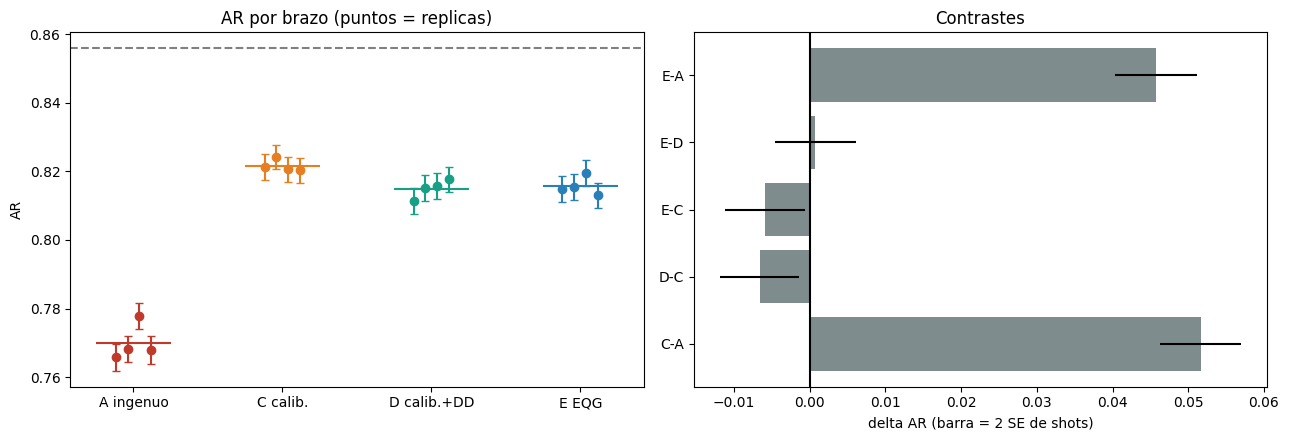

Guardado en /kaggle/working/eqg_ablation


In [10]:
report = {"experiment": "EQG ablation ABBA N=8 p=2", "calibration": CAL_STAMP0, "layouts": {"A": LAYOUT_A, "C": LAYOUT_C, "E_end": LAYOUT_E},
          "ideal": IDEAL, "stats": STATS, "contrasts": CONTRASTS, "works": works, "plans_E": plans_E, "dd_pulses": dd_pulses,
          "snap_pre": snap_pre, "snap_post": snap_post, "e_snaps": e_snaps, "jobs": _job_log, "used_s": USED_S, "est_s": EST_TOTAL}
(OUT / "report.json").write_text(json.dumps(report, indent=2, default=str))
col = {"A": "#c0392b", "C": "#e67e22", "D": "#16a085", "E": "#2980b9"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, a in enumerate("ACDE"):
    ws = [w for w in works if w["arm"] == a]
    ax[0].errorbar([k + 0.08 * (w["block"] * 2 + w["rep"] - 1.5) for w in ws], [w["ar"] for w in ws], yerr=[w["se_ar"] for w in ws],
                   fmt="o", color=col[a], capsize=3)
    ax[0].hlines(STATS[a]["ar"], k - 0.25, k + 0.25, color=col[a])
ax[0].axhline(IDEAL["ar"], color="gray", ls="--"); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["A ingenuo", "C calib.", "D calib.+DD", "E EQG"])
ax[0].set_ylabel("AR"); ax[0].set_title("AR por brazo (puntos = replicas)")
ax[1].barh([c["contrast"] for c in CONTRASTS], [c["delta"] for c in CONTRASTS], xerr=[2 * c["se"] for c in CONTRASTS], color="#7f8c8d")
ax[1].axvline(0, color="k"); ax[1].set_xlabel("delta AR (barra = 2 SE de shots)"); ax[1].set_title("Contrastes")
plt.tight_layout(); fig.savefig(OUT / "ablation.png", dpi=140, bbox_inches="tight"); plt.show()
print("Guardado en", OUT)


## Cómo leer los resultados

| Contraste | Si `SOPORTADO` (+) | Si no concluyente / signo opuesto |
|-----------|--------------------|-----------------------------------|
| **C−A** | Elegir layout por calibración ya aporta | Layout ingenuo no era tan malo ese día |
| **D−C** | DD aporta en AR (no solo en métrica `s`) | Pocas ventanas ociosas / ruido |
| **E−C** | Medir + reaccionar aporta sobre layout fijo | E no intervino o no mejoró AR |
| **E−D** | Política condicional ≥ DD siempre on | “Siempre DD” ganó; Juicio conservador |
| **E−A** | Replica el claim R1/R2 con más control de deriva | Revisar jobs y trayectoria de E |

**Notas honestas**

1. Si E termina con el mismo layout y DD que C o D, **E−C ≈ 0 por construcción**. Revisa la trayectoria impresa de E.
2. Orden palindrómico + bloques intercalados **reducen** la deriva, no la eliminan.
3. 4 réplicas es poco: `SOPORTADO` = consistente **en esta corrida**, no ley general.
4. El tiempo QPU dentro de un job se asume secuencial por orden de PUB.

**Entregables:** `eqg_ablation/report.json`, `ablation.png`.


## Licencia

**Edge Quantum Guard (EQG)** — ablación experimental ABBA.  
Copyright (c) 2026 Arturo Salvador Balderas Hernández.  
Licencia del proyecto: **Elastic License 2.0**.  
Qiskit permanece bajo Apache-2.0.  
Cola ≠ cuenta. Un solo experimento no prueba causalidad permanente.